# Module 3: Vision Transformers in PyTorch

> **Assignment (12 points):** CNN-ViT hybrid in PyTorch — train a base hybrid `model` and a larger `model_test` (embed_dim=768, heads=12, depth=12), then compare validation loss and training time.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
PROJECT_ROOT = pathlib.Path(os.path.abspath(os.getcwd()))
for p in [PROJECT_ROOT] + list(PROJECT_ROOT.parents):
    if (p / 'images_dataSAT').is_dir():
        PROJECT_ROOT = p
        break
os.chdir(PROJECT_ROOT)
print('Project root:', PROJECT_ROOT)

Project root: D:\امتحان


In [2]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

data_dir = './images_dataSAT'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


### Task 1: Create `train_transform` for the training dataset

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(45),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
print(train_transform)

Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.2)
    RandomRotation(degrees=[-45.0, 45.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Task 2: Create `val_transform` for the validation dataset

In [4]:
val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
print(val_transform)

Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Task 3: Create `train_loader` and `val_loader` using `train_dataset` and `val_dataset`

In [5]:
train_dataset = datasets.ImageFolder(data_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(data_dir, transform=val_transform)

train_dataset, _ = random_split(train_dataset, [600, len(train_dataset) - 600])
val_dataset,   _ = random_split(val_dataset, [400, len(val_dataset) - 400])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
print('Train batches:', len(train_loader), '| Val batches:', len(val_loader))

Train batches: 19 | Val batches: 13


## CNN-ViT hybrid model definition

In [6]:
class CNNViTHybrid(nn.Module):
    def __init__(self, embed_dim=128, num_heads=4, transformer_depth=4, num_classes=1):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.num_patches = 4 * 4                       # CNN feature map -> tokens
        self.patch_embed = nn.Linear(256, embed_dim)   # project each token to embed_dim
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches, embed_dim) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=4 * embed_dim,
            batch_first=True, dropout=0.1, norm_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=transformer_depth)
        self.head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Linear(embed_dim, num_classes))

    def forward(self, x):
        x = self.cnn(x)                                # (B, 256, 4, 4)
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1).reshape(B, H * W, C) # (B, 16, 256) tokens
        x = self.patch_embed(x) + self.pos_embed       # (B, 16, embed_dim)
        x = self.transformer(x)                        # transformer over 16 tokens
        x = x.mean(dim=1)                              # global pooling
        return self.head(x)

## Generic training helper

In [7]:
def train_model(model, train_loader, val_loader, epochs=5, lr=1e-4, device='cpu'):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    start = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        for images, labels in tqdm(train_loader, desc=f'Epoch {epoch + 1}/{epochs}', leave=False):
            images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            train_correct += (preds == labels).sum().item()
            train_total += labels.numel()

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item() * images.size(0)
                preds = (torch.sigmoid(outputs) > 0.5).float()
                val_correct += (preds == labels).sum().item()
                val_total += labels.numel()

        hist['train_loss'].append(train_loss / train_total)
        hist['val_loss'].append(val_loss / val_total)
        hist['train_acc'].append(train_correct / train_total)
        hist['val_acc'].append(val_correct / val_total)

    elapsed = time.time() - start
    return hist, elapsed

## Train the base hybrid `model` (small config)

In [8]:
model = CNNViTHybrid(embed_dim=128, num_heads=4, transformer_depth=4)
history_model, time_model = train_model(model, train_loader, val_loader, epochs=5, device=device)
print(f'Base ViT  -> val_acc={history_model["val_acc"][-1]:.4f}, training time={time_model:.1f}s')

Epoch 1/5:   0%|          | 0/19 [00:00<?, ?it/s]

Epoch 1/5:   5%|▌         | 1/19 [00:00<00:01,  9.90it/s]

Epoch 1/5:  16%|█▌        | 3/19 [00:00<00:01, 12.40it/s]

Epoch 1/5:  26%|██▋       | 5/19 [00:00<00:01, 12.29it/s]

Epoch 1/5:  37%|███▋      | 7/19 [00:00<00:00, 12.02it/s]

Epoch 1/5:  47%|████▋     | 9/19 [00:00<00:00, 12.25it/s]

... (42 outputs left out)

Epoch 5/5:  74%|███████▎  | 14/19 [00:01<00:00, 12.83it/s]

Epoch 5/5:  84%|████████▍ | 16/19 [00:01<00:00, 12.45it/s]

Epoch 5/5:  95%|█████████▍| 18/19 [00:01<00:00, 12.78it/s]

Base ViT  -> val_acc=0.8525, training time=9.0s


### Task 4: Design and train the CNN-ViT hybrid `model_test` — epochs=5, mlp heads=12, embed_dim=768, transformer block depth=12

In [9]:
model_test = CNNViTHybrid(embed_dim=768, num_heads=12, transformer_depth=12)
history_model_test, time_model_test = train_model(model_test, train_loader, val_loader, epochs=5, device=device)
print(f'model_test -> val_acc={history_model_test["val_acc"][-1]:.4f}, training time={time_model_test:.1f}s')

os.makedirs('models', exist_ok=True)
torch.save(model_test.state_dict(), 'models/pytorch_vit_test.pth')
print('model_test saved -> models/pytorch_vit_test.pth')

Epoch 1/5:   0%|          | 0/19 [00:00<?, ?it/s]

Epoch 1/5:   5%|▌         | 1/19 [00:00<00:14,  1.21it/s]

Epoch 1/5:  11%|█         | 2/19 [00:01<00:13,  1.24it/s]

Epoch 1/5:  16%|█▌        | 3/19 [00:02<00:13,  1.22it/s]

Epoch 1/5:  21%|██        | 4/19 [00:03<00:12,  1.23it/s]

Epoch 1/5:  26%|██▋       | 5/19 [00:04<00:11,  1.22it/s]

... (92 outputs left out)

Epoch 5/5:  95%|█████████▍| 18/19 [00:14<00:00,  1.23it/s]

Epoch 5/5: 100%|██████████| 19/19 [00:15<00:00,  1.30it/s]

model_test -> val_acc=0.8300, training time=85.9s


model_test saved -> models/pytorch_vit_test.pth


### Task 5: Compare the performance of `model` with `model_test` by plotting the validation loss

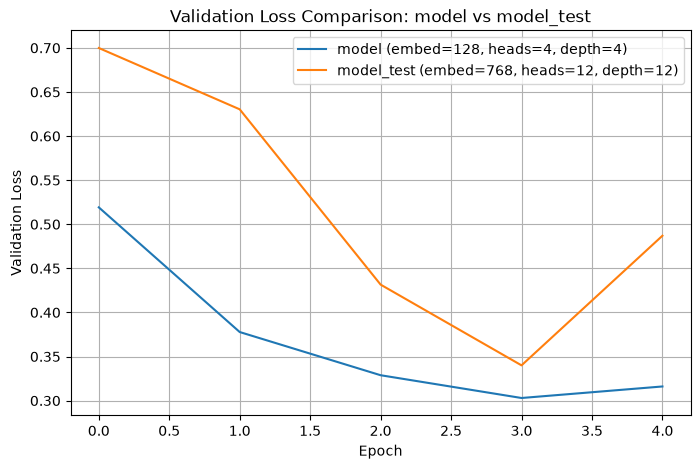

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history_model['val_loss'], label='model (embed=128, heads=4, depth=4)')
plt.plot(history_model_test['val_loss'], label='model_test (embed=768, heads=12, depth=12)')
plt.title('Validation Loss Comparison: model vs model_test')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.savefig('models/vit_pytorch_val_loss_comparison.png')
plt.show()

### Task 6: Compare the training times of `model` with `model_test`

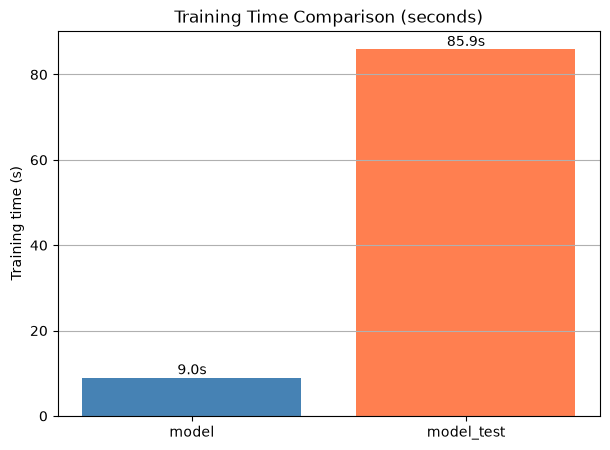

In [11]:
times = [time_model, time_model_test]
names = ['model', 'model_test']

plt.figure(figsize=(7, 5))
bars = plt.bar(names, times, color=['steelblue', 'coral'])
plt.title('Training Time Comparison (seconds)')
plt.ylabel('Training time (s)')
for bar, t in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width() / 2, t, f'{t:.1f}s', ha='center', va='bottom')
plt.grid(True, axis='y')
plt.savefig('models/vit_pytorch_time_comparison.png')
plt.show()